# 🩺 Bangla Prescription Analyzer — Training in Google Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/bangla-prescription-analyzer/blob/main/notebooks/train_colab.ipynb)

**Pipeline:** handwritten medicine-word image → CNN (78 medicine classes) → generic name → Bangla description (uses, side effects, cautions).

Dataset: [Doctor's Handwritten Prescription BD dataset](https://www.kaggle.com/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset) — 4,680 word images, 78 medicines, 60/20/20 split.

Run the cells top to bottom. Expected time on a free T4 GPU: ~15–25 min for EfficientNet-B0.

## Step 1 — Use a GPU runtime
Menu: **Runtime → Change runtime type → T4 GPU → Save**. Then run the cell below; you should see a Tesla T4.

In [1]:
!nvidia-smi

Fri Nov  6 17:31:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 2 — Mount Google Drive
Checkpoints are saved to Drive so they survive when Colab disconnects.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

RUN_DIR = '/content/drive/MyDrive/rx_runs/effb0'   # change the name for each experiment
!mkdir -p $RUN_DIR

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 3 — Get the project code
**Option A (recommended):** after you push this repo to GitHub, clone it here (public repo).
**Option B:** private repo → use a GitHub token, or upload the zip with the file browser and unzip.

In [2]:
REPO_URL = 'https://github.com/Shams-Sajid-Rahman/bangla-prescription-analyzer.git'  # <-- edit

import os
if not os.path.exists('/content/bangla-prescription-analyzer'):
    !git clone $REPO_URL /content/bangla-prescription-analyzer
%cd /content/bangla-prescription-analyzer
!git pull

/content/bangla-prescription-analyzer
Already up to date.


In [3]:
# Colab already ships torch/torchvision/pandas/sklearn — install only what is missing
!pip install -q timm gradio kagglehub
import torch, timm; print('torch', torch.__version__, '| timm', timm.__version__, '| cuda', torch.cuda.is_available())

torch 2.14.1+cpu | timm 1.0.31 | cuda False


## Step 4 — Download the dataset from Kaggle
`kagglehub` downloads public datasets directly. If it asks for credentials: Kaggle → Settings → **API → Create New Token**, then add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's 🔑 **Secrets** panel (left sidebar) and enable notebook access.

In [4]:
import os, kagglehub
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
except Exception:
    pass  # public dataset usually works without a token

DATA_ROOT = kagglehub.dataset_download('mamun1113/doctors-handwritten-prescription-bd-dataset')
print('Dataset at:', DATA_ROOT)
!find "$DATA_ROOT" -maxdepth 3 -type d
!find "$DATA_ROOT" -name '*.csv'

100%|██████████| 19.1M/19.1M [00:00<00:00, 25.3MB/s]

Extracting files...


Dataset at: /root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1
/root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1
/root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1/Doctor’s Handwritten Prescription BD dataset
/root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1/Doctor’s Handwritten Prescription BD dataset/Testing
/root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1/Doctor’s Handwritten Prescription BD dataset/Testing/testing_words
/root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1/Doctor’s Handwritten Prescription BD dataset/Training
/root/.cache/kagglehub/datasets/mamun1113/doctors-handwritten-prescription-bd-dataset/versions/1/Doctor’s Handwritten Prescription BD dataset/Training/training_words
/root/.cache/kagglehu

## Step 5 — Explore the data (EDA)

In [6]:
import sys; sys.path.insert(0, '.')
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from src.data import load_all

frames = load_all(DATA_ROOT)
for split, df in frames.items():
    print(f"{split:5s} {len(df):5d} images | {df['medicine'].nunique()} medicines | {df['generic'].nunique()} generics")

train = frames['train']
display(train.head())
print('\nImages per class (train):'); print(train['medicine'].value_counts().describe())
print('\nMedicines per generic:'); display(train.drop_duplicates('medicine').groupby('generic')['medicine'].apply(list))

test    780 images | 78 medicines | 15 generics
train  3120 images | 78 medicines | 15 generics
val     780 images | 78 medicines | 15 generics


,path,medicine,generic
0,/root/.cache/kagglehub/datasets/mamun1113/doct...,Aceta,Paracetamol
1,/root/.cache/kagglehub/datasets/mamun1113/doct...,Aceta,Paracetamol
2,/root/.cache/kagglehub/datasets/mamun1113/doct...,Aceta,Paracetamol
3,/root/.cache/kagglehub/datasets/mamun1113/doct...,Aceta,Paracetamol
4,/root/.cache/kagglehub/datasets/mamun1113/doct...,Aceta,Paracetamol



Images per class (train):
count    78.0
mean     40.0
std       0.0
min      40.0
25%      40.0
50%      40.0
75%      40.0
max      40.0
Name: count, dtype: float64

Medicines per generic:


,medicine
generic,
Azithromycin Dihydrate,"[Azithrocin, Azyth, Az, Rozith, Tridosil, Zith..."
Azithromycin Dihydrate (Ophthalmic),[Romycin]
Baclofen,"[Bacaid, Backtone, Baclofen, Baclon, Bacmax, B..."
Cetirizine Hydrochloride,"[Alatrol, Atrizin, Cetisoft, Etizin, Rhinil]"
Clonazepam,"[Denixil, Disopan, Leptic, Rivotril]"
Esomeprazole,"[Esonix, Esoral, Exium, Maxima, Maxpro, Nexcap..."
Fexofenadine Hydrochloride,"[Axodin, Dinafex, Fenadin, Fexofast, Fexo, Fix..."
Fluconazole,"[Canazole, Candinil, Conaz, Diflu, Flugal, Luc..."
Ketoconazole (Cream),[Nizoder]


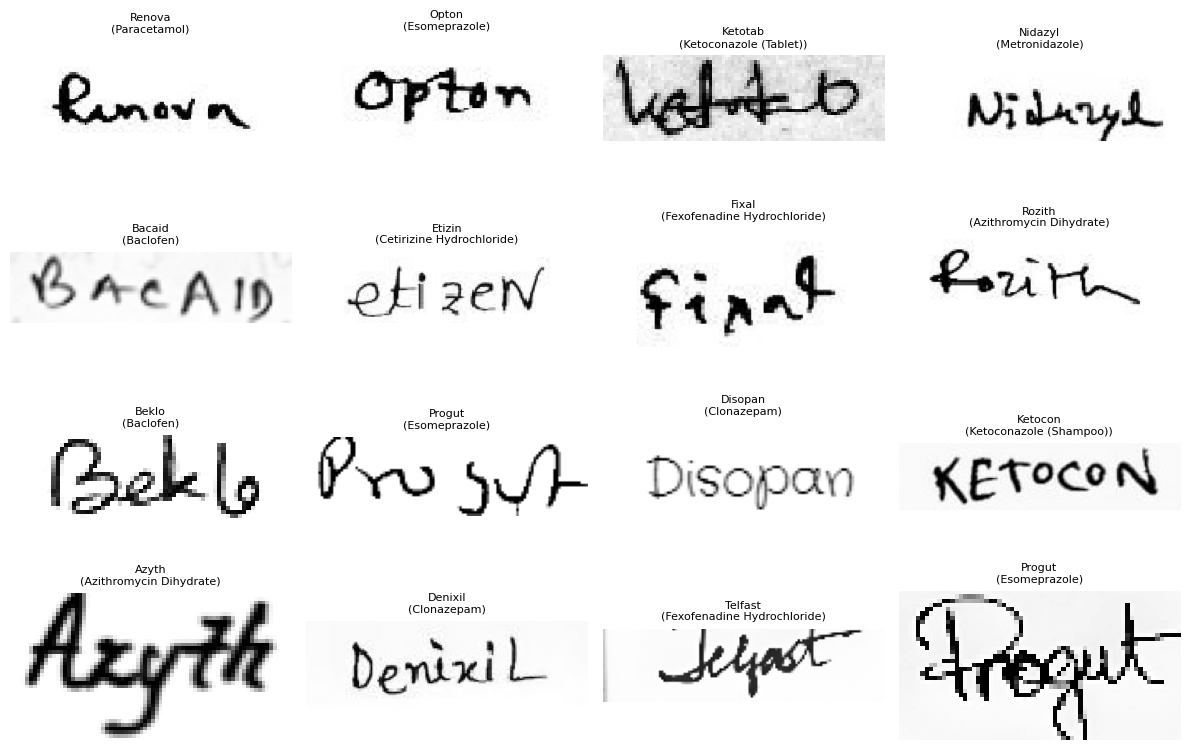

                w           h
count  300.000000  300.000000
mean   154.916667   52.423333
std     67.505454   24.771007
min     47.000000   14.000000
25%    107.750000   32.000000
50%    150.500000   52.000000
75%    195.000000   67.250000
max    683.000000  147.000000


In [7]:
sample = train.sample(16, random_state=0)
fig, axes = plt.subplots(4, 4, figsize=(12, 8))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(r.path).convert('L'), cmap='gray'); ax.set_title(f"{r.medicine}\n({r.generic})", fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

sizes = pd.DataFrame([Image.open(p).size for p in train.path.sample(300, random_state=0)], columns=['w', 'h'])
print(sizes.describe())

## Step 6 — Train
Key choices (see `src/train.py`): ImageNet-pretrained backbone, AdamW, warm-up + cosine LR, label smoothing, mixed precision, early stopping, light augmentation (small rotation/shear/blur — **no flips**, because flipped text is a different word).

Try other backbones later by changing `--model`: `convnext_tiny`, `resnet50`, `mobilenetv3_large_100`, `efficientnet_b3`.

In [8]:
!python -m src.train --data_root "$DATA_ROOT" --out_dir "$RUN_DIR" \
    --model efficientnet_b0 --img_size 224 --epochs 40 --batch_size 64 --lr 3e-4

Device: cuda (Tesla T4)
test :   780 images, 78 classes
train:  3120 images, 78 classes
val  :   780 images, 78 classes

model.safetensors: downloading bytes:  43% 9.12M/21.4M [00:00<00:00, 22.6MB/s,   ???B/s  ]
model.safetensors: downloading bytes: 100% 20.2M/20.2M [00:00<00:00, 29.1MB/s, 1.96MB/s  ]
model.safetensors: reconstructing file: 100% 21.4M/21.4M [00:00<00:00, 30.8MB/s, 2.10MB/s  ]
/content/bangla-prescription-analyzer/src/train.py:131: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
ep   1 | train loss 4.637 acc 0.021 | val loss 4.335 top1 0.047 top5 0.147 | 26.3s
  ✓ new best val top1 = 0.0474 -> saved /content/drive/M

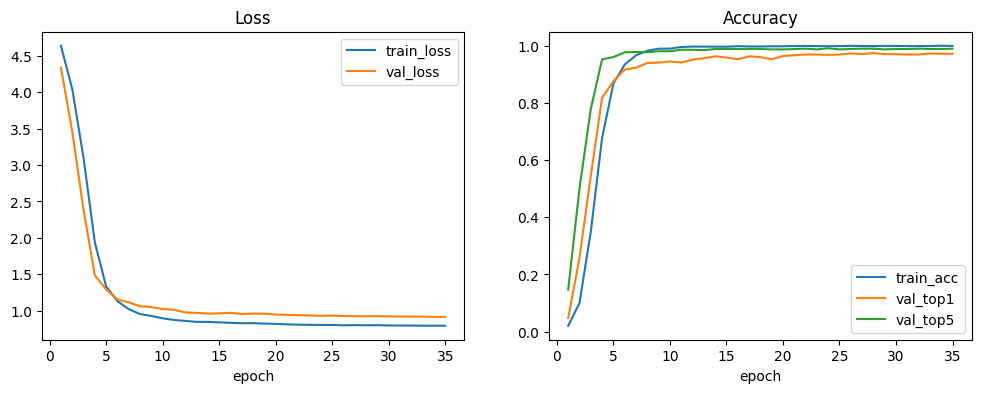

,epoch,train_loss,train_acc,val_loss,val_top1,val_top5,lr,sec
30,31,0.797633,0.998698,0.920586,0.969231,0.988462,0.000040,17.9
31,32,0.796935,0.998698,0.920533,0.969231,0.989744,0.000032,18.5
32,33,0.795036,0.999023,0.920738,0.973077,0.988462,0.000024,17.6
33,34,0.795224,1.000000,0.915728,0.971795,0.988462,0.000018,17.6
34,35,0.794831,0.999349,0.915918,0.971795,0.989744,0.000013,17.8


In [9]:
import json
h = pd.DataFrame(json.load(open(f'{RUN_DIR}/history.json')))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h.plot(x='epoch', y=['train_loss', 'val_loss'], ax=ax[0], title='Loss')
h.plot(x='epoch', y=['train_acc', 'val_top1', 'val_top5'], ax=ax[1], title='Accuracy')
plt.show(); h.tail()

## Step 7 — Evaluate on the held-out Testing split
Reports top-1 / top-5 accuracy, macro-F1, and **generic accuracy** (a wrong brand with the same active ingredient is a less dangerous mistake).

{
  "split": "test",
  "n": 780,
  "top1_acc": 0.9128205128205128,
  "top5_acc": 0.9653846153846154,
  "macro_f1": 0.9093995016514871,
  "generic_acc": 0.9551282051282052
}
68 misclassified images listed in /content/drive/MyDrive/rx_runs/effb0/misclassified.csv


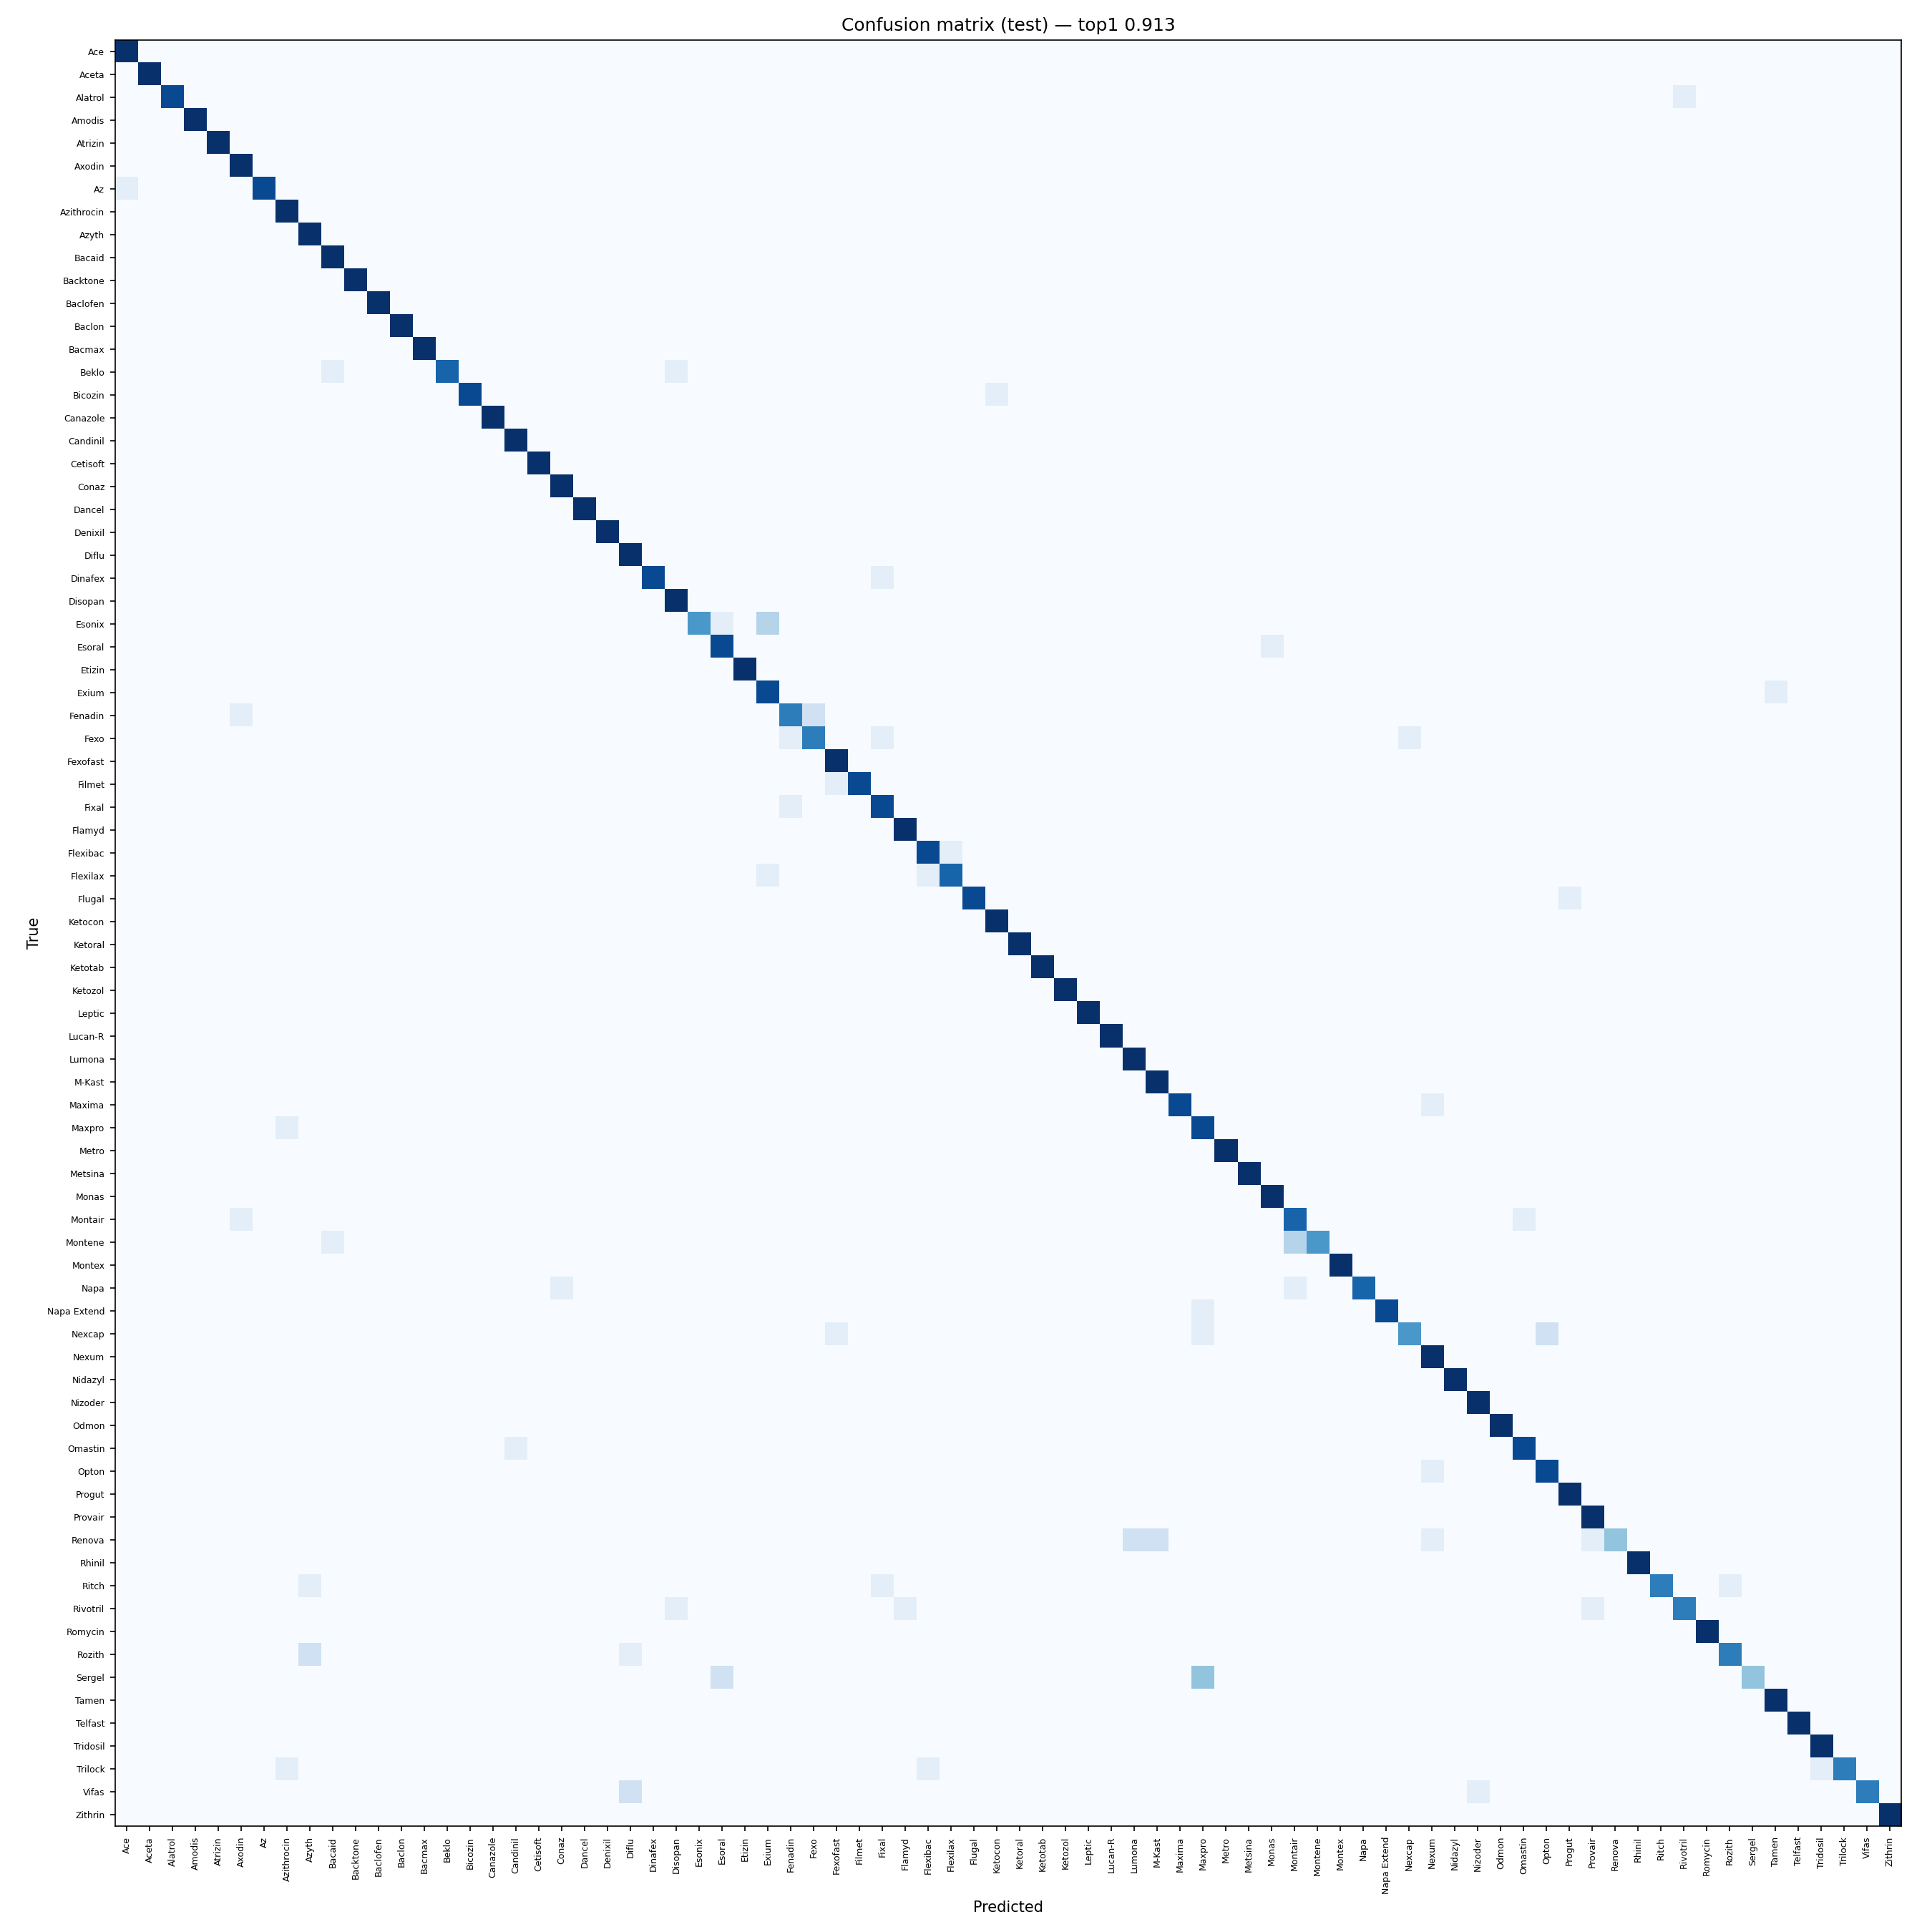

In [10]:
!python -m src.evaluate --data_root "$DATA_ROOT" --run_dir "$RUN_DIR"
from IPython.display import Image as IPImage
IPImage(f'{RUN_DIR}/confusion_matrix.png', width=900)

In [11]:
wrong = pd.read_csv(f'{RUN_DIR}/misclassified.csv')
print(len(wrong), 'mistakes'); display(wrong.groupby(['medicine', 'pred']).size().sort_values(ascending=False).head(15))

68 mistakes


medicine  pred   
Sergel    Maxpro     4
Esonix    Exium      3
Montene   Montair    3
Renova    Lumona     2
          M-Kast     2
Fenadin   Fexo       2
Nexcap    Opton      2
Rozith    Azyth      2
Sergel    Esoral     2
Vifas     Diflu      2
Exium     Tamen      1
Fenadin   Axodin     1
Fexo      Fenadin    1
          Fixal      1
Dinafex   Fixal      1
dtype: int64

## Step 8 — Bangla knowledge base
Check which generic names from the dataset still need a Bangla entry in `data/bangla_generic_info.json`.

In [12]:
!python -m src.knowledge_base check --label_map "$RUN_DIR/label_map.json"

15 generics in dataset, 11 covered by the KB.
Add Bangla entries for these in data/bangla_generic_info.json:
  - Azithromycin Dihydrate (Ophthalmic)
  - Ketoconazole (Cream)
  - Ketoconazole (Shampoo)
  - Ketoconazole (Tablet)


### (Optional) Enrich from a large Bangladesh medicine database
Downloads `generic.csv` from the MIT-licensed *Medicine Dataset of Bangladesh* on Hugging Face and builds `data/kb_extra.json` (English descriptions; add `--translate` for machine translation EN→BN with BanglaT5, slower and must be reviewed).

In [13]:
from huggingface_hub import hf_hub_download
gcsv = hf_hub_download('ArnobBot/Medicine-Dataset-of-Bangladesh', 'generic.csv', repo_type='dataset')
print(pd.read_csv(gcsv, nrows=2).columns.tolist())
!python -m src.knowledge_base build --generic_csv "$gcsv" --label_map "$RUN_DIR/label_map.json"
# with translation:  !pip -q install transformers sentencepiece && python -m src.knowledge_base build ... --translate

generic.csv:   0%|          | 0.00/8.52M [00:00<?, ?B/s]

['generic id', 'generic name', 'slug', 'monograph link', 'drug class', 'indication', 'indication description', 'therapeutic class description', 'pharmacology description', 'dosage description', 'administration description', 'interaction description', 'contraindications description', 'side effects description', 'pregnancy and lactation description', 'precautions description', 'pediatric usage description', 'overdose effects description', 'duration of treatment description', 'reconstitution description', 'storage conditions description', 'descriptions count']
Using columns: {'name': 'generic name', 'uses_en': 'indication description', 'side_effects_en': 'side effects description', 'caution_en': 'precautions description', 'class_en': 'drug class'}
Wrote 15 entries to /content/bangla-prescription-analyzer/data/kb_extra.json


## Step 9 — Analyze images (Bangla report)

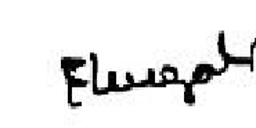

Ground truth: Flugal


### 💊 শনাক্তকৃত ওষুধ: **Flugal**
- নির্ভরযোগ্যতা (confidence): **94.3%**
- জেনেরিক নাম: **Fluconazole** (ফ্লুকোনাজল)

**ওষুধের শ্রেণি:** অ্যান্টিফাঙ্গাল (ছত্রাকরোধী)

**ব্যবহার:** ছত্রাক সংক্রমণ, যেমন যোনিপথের ক্যানডিডিয়াসিস, মুখ ও খাদ্যনালির ক্যানডিডা সংক্রমণ এবং ত্বক ও নখের কিছু ছত্রাক সংক্রমণ।

**সাধারণ পার্শ্বপ্রতিক্রিয়া:** বমিভাব, পেটব্যথা, ডায়রিয়া, মাথাব্যথা, ত্বকে ফুসকুড়ি।

**সতর্কতা:** লিভার বা হৃদস্পন্দনের সমস্যা থাকলে সাবধানতা প্রয়োজন। অনেক ওষুধের সাথে মিথস্ক্রিয়া করে। গর্ভাবস্থায় চিকিৎসকের পরামর্শ ছাড়া সেবন করবেন না।

**অন্যান্য সম্ভাব্য নাম:** Flamyd (0%), Sergel (0%)

---
⚠️ সতর্কতা: এটি একটি শিক্ষামূলক/গবেষণা প্রকল্পের স্বয়ংক্রিয় ফলাফল এবং ভুল হতে পারে। ওষুধ সেবনের আগে অবশ্যই চিকিৎসক বা ফার্মাসিস্টের সাথে মিলিয়ে নিন। এখানে কোনো ওষুধের মাত্রা (ডোজ) দেওয়া হয়নি — প্রেসক্রিপশনে লেখা মাত্রাই অনুসরণ করুন।

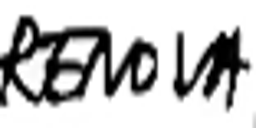

Ground truth: Renova


### 💊 শনাক্তকৃত ওষুধ: **M-Kast**
- নির্ভরযোগ্যতা (confidence): **9.0%**
- জেনেরিক নাম: **Montelukast Sodium** (মন্টেলুকাস্ট)
- ⚠️ মডেল এই শব্দটি নিয়ে নিশ্চিত নয় — নিচের বিকল্পগুলোও দেখুন এবং ফার্মাসিস্টের সাথে মিলিয়ে নিন।

**ওষুধের শ্রেণি:** লিউকোট্রিন রিসেপ্টর অ্যান্টাগনিস্ট

**ব্যবহার:** হাঁপানি (অ্যাজমা) প্রতিরোধ ও দীর্ঘমেয়াদি নিয়ন্ত্রণ, ব্যায়ামজনিত শ্বাসকষ্ট প্রতিরোধ এবং অ্যালার্জিক রাইনাইটিস।

**সাধারণ পার্শ্বপ্রতিক্রিয়া:** মাথাব্যথা, পেটব্যথা, ক্লান্তি; কদাচিৎ মেজাজ পরিবর্তন, দুঃস্বপ্ন বা ঘুমের সমস্যা।

**সতর্কতা:** হঠাৎ শুরু হওয়া হাঁপানির টান উপশমে এটি কাজ করে না — সেজন্য ইনহেলার প্রয়োজন। আচরণ বা মেজাজে অস্বাভাবিক পরিবর্তন দেখা দিলে দ্রুত চিকিৎসককে জানান।

**অন্যান্য সম্ভাব্য নাম:** Bicozin (6%), Fexofast (5%)

---
⚠️ সতর্কতা: এটি একটি শিক্ষামূলক/গবেষণা প্রকল্পের স্বয়ংক্রিয় ফলাফল এবং ভুল হতে পারে। ওষুধ সেবনের আগে অবশ্যই চিকিৎসক বা ফার্মাসিস্টের সাথে মিলিয়ে নিন। এখানে কোনো ওষুধের মাত্রা (ডোজ) দেওয়া হয়নি — প্রেসক্রিপশনে লেখা মাত্রাই অনুসরণ করুন।

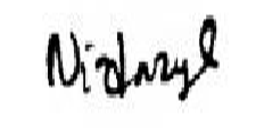

Ground truth: Nidazyl


### 💊 শনাক্তকৃত ওষুধ: **Nidazyl**
- নির্ভরযোগ্যতা (confidence): **37.0%**
- জেনেরিক নাম: **Metronidazole** (মেট্রোনিডাজল)
- ⚠️ মডেল এই শব্দটি নিয়ে নিশ্চিত নয় — নিচের বিকল্পগুলোও দেখুন এবং ফার্মাসিস্টের সাথে মিলিয়ে নিন।

**ওষুধের শ্রেণি:** অ্যান্টিবায়োটিক ও অ্যান্টিপ্রোটোজোয়াল

**ব্যবহার:** অ্যামিবিক আমাশয়, জিয়ার্ডিয়াসিস, অ্যানারোবিক ব্যাকটেরিয়াজনিত সংক্রমণ, দাঁত ও মাড়ির সংক্রমণ এবং ব্যাকটেরিয়াল ভ্যাজাইনোসিস।

**সাধারণ পার্শ্বপ্রতিক্রিয়া:** মুখে ধাতব স্বাদ, বমিভাব, ক্ষুধামন্দা, পেটের অস্বস্তি, প্রস্রাবের রং গাঢ় হওয়া।

**সতর্কতা:** সেবনকালে এবং কোর্স শেষ হওয়ার পর অন্তত ৪৮ ঘণ্টা মদ্যপান সম্পূর্ণ নিষেধ। পূর্ণ কোর্স শেষ করুন।

**অন্যান্য সম্ভাব্য নাম:** Nexcap (5%), M-Kast (2%)

---
⚠️ সতর্কতা: এটি একটি শিক্ষামূলক/গবেষণা প্রকল্পের স্বয়ংক্রিয় ফলাফল এবং ভুল হতে পারে। ওষুধ সেবনের আগে অবশ্যই চিকিৎসক বা ফার্মাসিস্টের সাথে মিলিয়ে নিন। এখানে কোনো ওষুধের মাত্রা (ডোজ) দেওয়া হয়নি — প্রেসক্রিপশনে লেখা মাত্রাই অনুসরণ করুন।

In [14]:
from IPython.display import Markdown, display
from src.analyzer import PrescriptionAnalyzer
an = PrescriptionAnalyzer(RUN_DIR)
test = frames['test'].sample(3, random_state=1)
for _, r in test.iterrows():
    display(Image.open(r.path).convert('L').resize((256, 128)))
    print('Ground truth:', r.medicine)
    display(Markdown(an.to_bangla_report(an.analyze(r.path))))

## Step 10 — Web demo (Gradio, public link)

In [15]:
!python app/app.py --run_dir "$RUN_DIR" --share

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://a1cc7d5f731bd9bc81.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/bangla-prescription-analyzer/app/app.py", line 45, in <module>
    build_ui(PrescriptionAnalyzer(a.run_dir)).launch(share=a.share)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3770

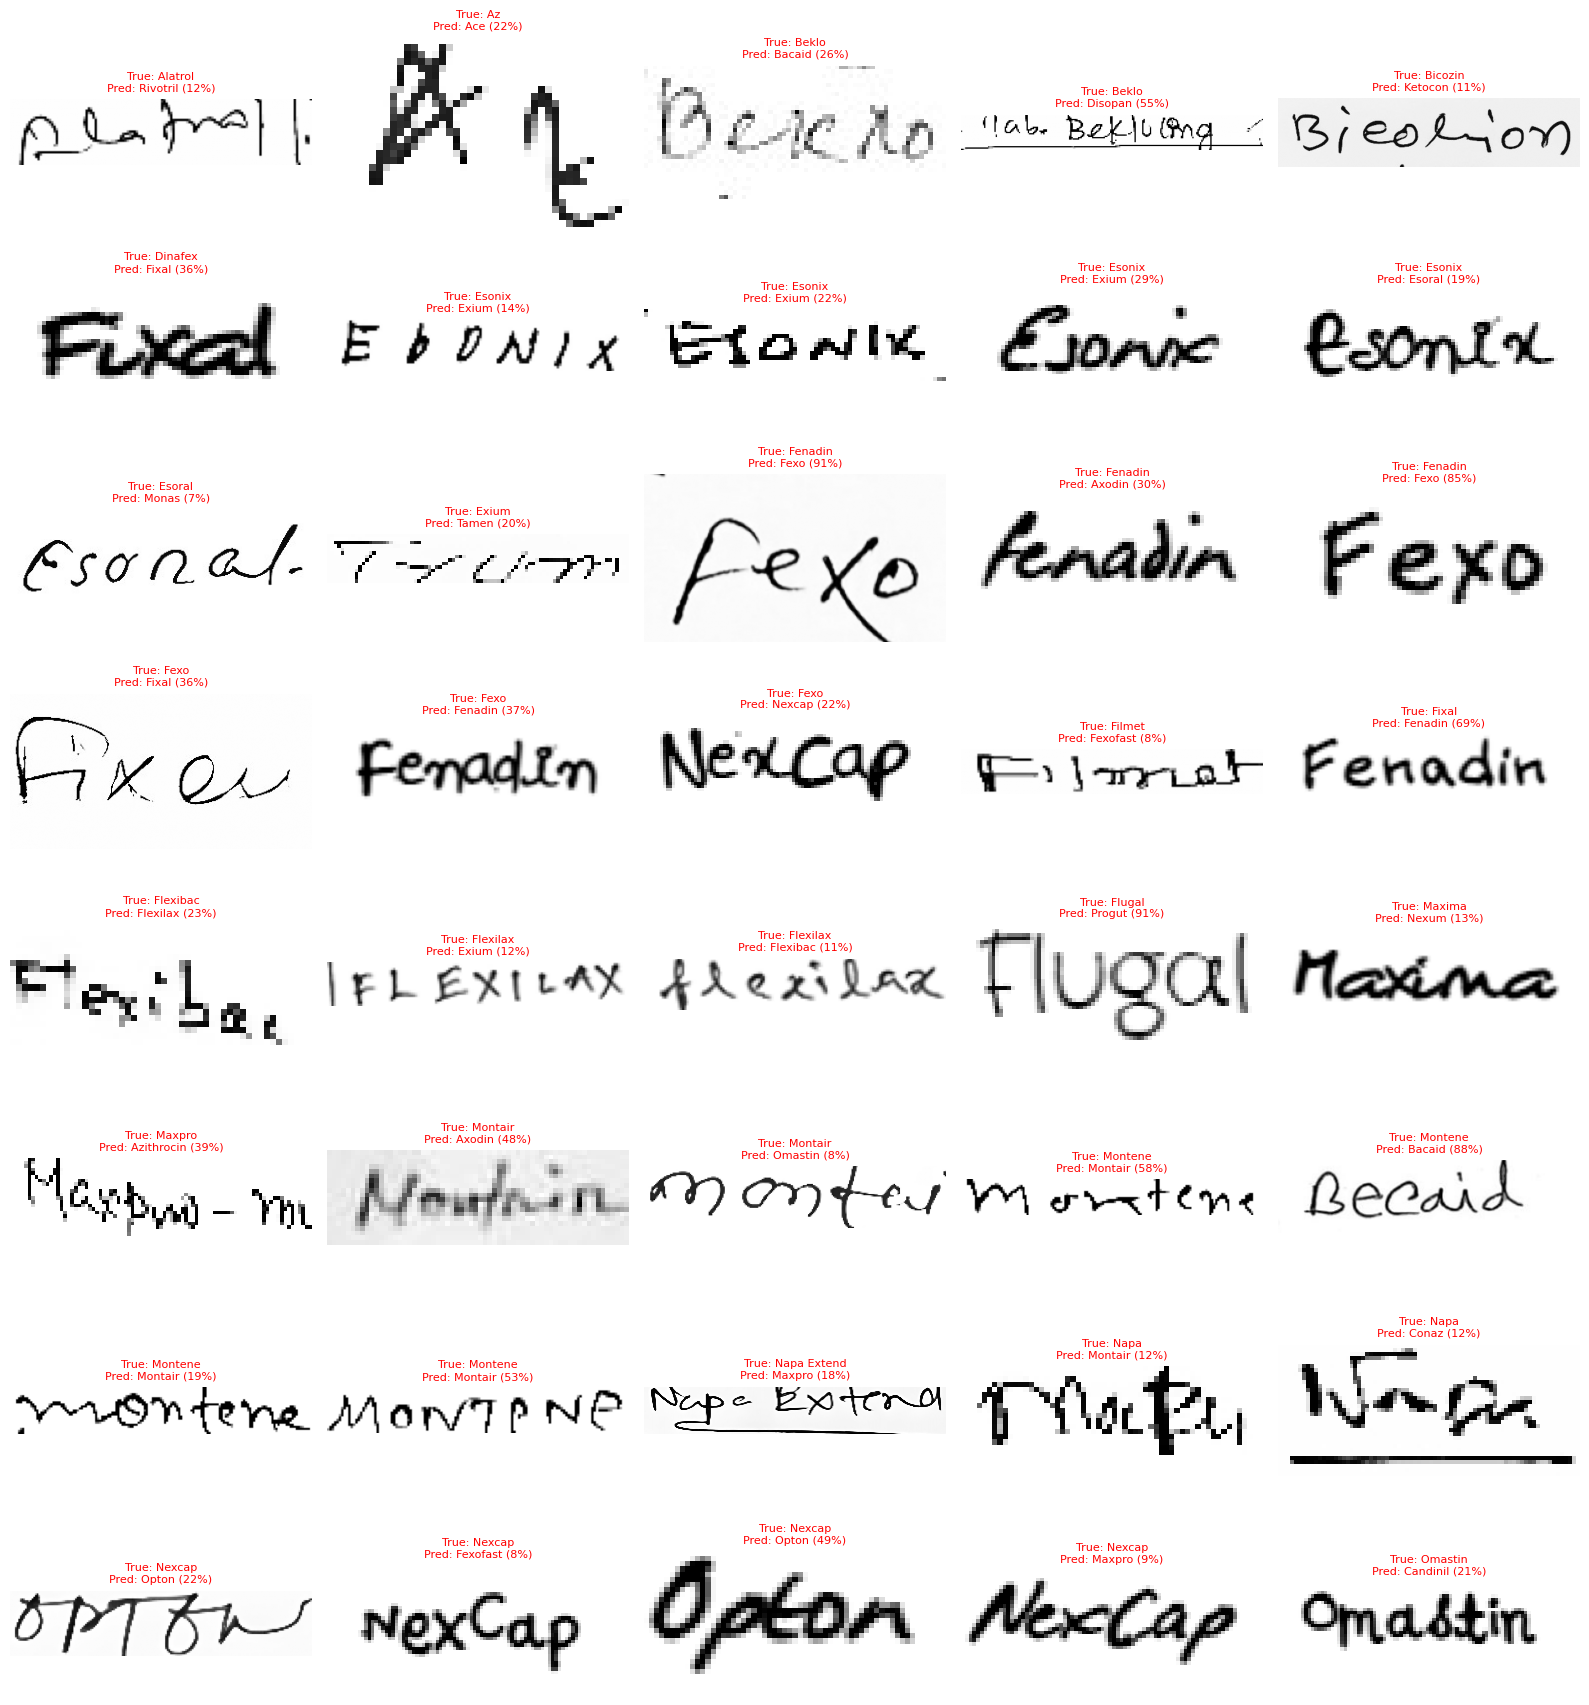

In [17]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
wrong = pd.read_csv(f'{RUN_DIR}/misclassified.csv')
n = min(len(wrong), 40)
fig, axes = plt.subplots((n + 4) // 5, 5, figsize=(16, 2.2 * ((n + 4) // 5)))
for ax in axes.flat: ax.axis('off')
for ax, (_, r) in zip(axes.flat, wrong.head(n).iterrows()):
    ax.imshow(Image.open(r.path).convert('L'), cmap='gray')
    ax.set_title(f'True: {r.medicine}\nPred: {r.pred} ({r.conf:.0%})', fontsize=8, color='red')
plt.tight_layout(); plt.show()

split
test    68
val     22
Name: count, dtype: int64


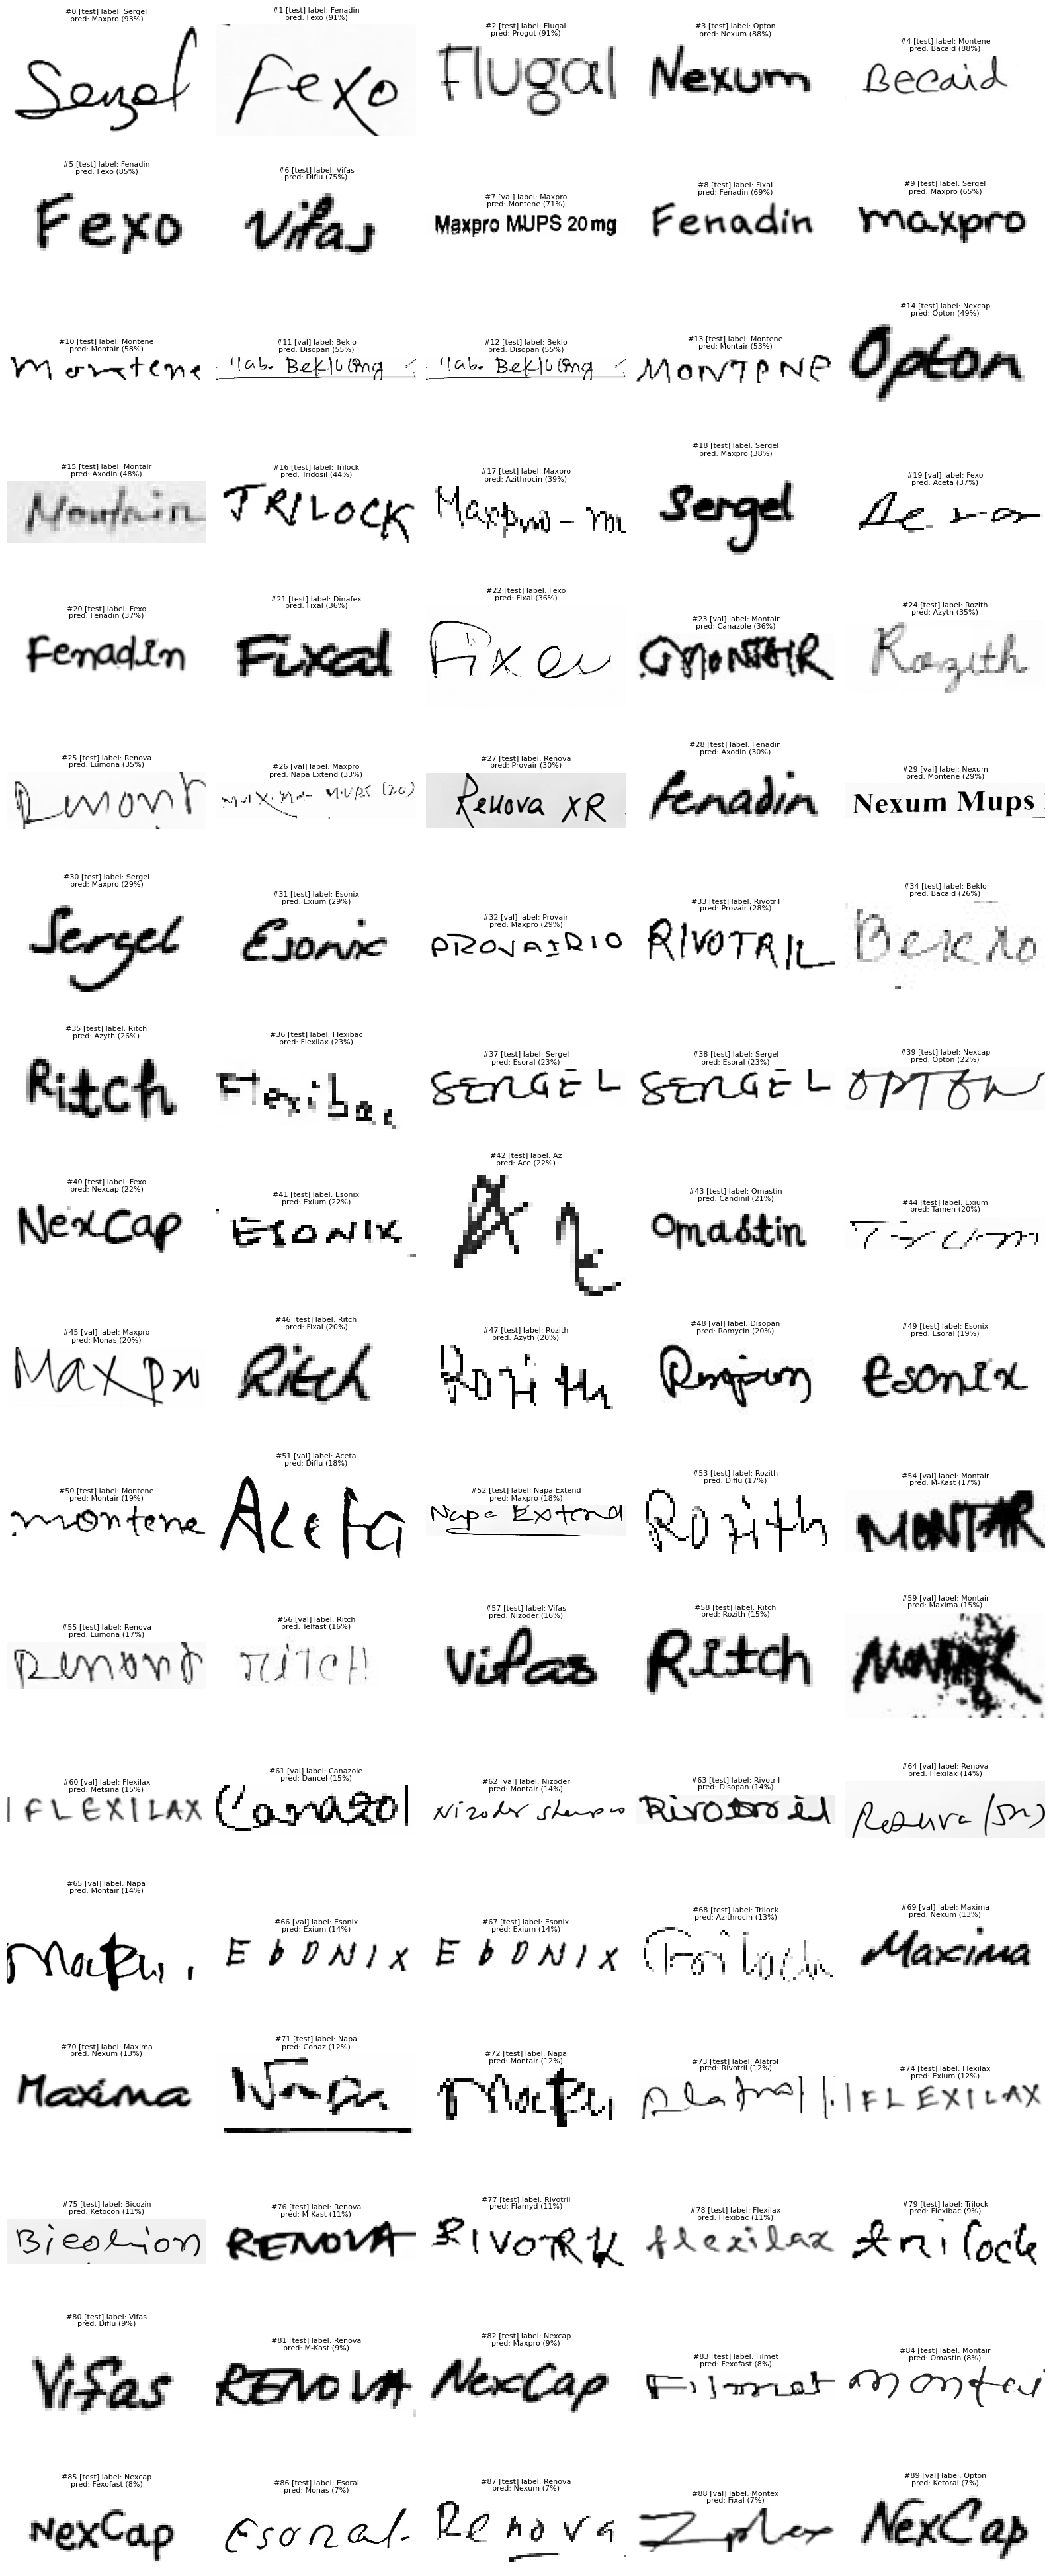

In [18]:
import torch, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader
from src.data import LabelMap, PrescriptionWords, load_all, build_transforms
from src.model import load_checkpoint

lm = LabelMap.load(f'{RUN_DIR}/label_map.json')
model, cfg = load_checkpoint(f'{RUN_DIR}/best.pt', len(lm.classes), 'cuda')
tf = build_transforms(cfg['img_size'], train=False)
fr = load_all(DATA_ROOT)
sus = []
with torch.no_grad():
    for split, df in fr.items():
        dl = DataLoader(PrescriptionWords(df, lm, tf), batch_size=64)
        P = torch.cat([model(x.cuda()).softmax(1).cpu() for x, _ in dl])
        conf, pred = P.max(1)
        d = df.assign(split=split, pred=[lm.classes[i] for i in pred], conf=conf.numpy())
        sus.append(d[d.pred != d.medicine])
sus = pd.concat(sus).sort_values('conf', ascending=False).reset_index(drop=True)
print(sus.split.value_counts())

# show them (index number on each image, so you can refer to it)
n = len(sus)
fig, axes = plt.subplots((n + 4) // 5, 5, figsize=(16, 2.2 * ((n + 4) // 5)))
for ax in axes.flat: ax.axis('off')
for ax, (i, r) in zip(axes.flat, sus.iterrows()):
    ax.imshow(Image.open(r.path).convert('L'), cmap='gray')
    ax.set_title(f'#{i} [{r.split}] label: {r.medicine}\npred: {r.pred} ({r.conf:.0%})', fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
rev = sus[['split', 'path', 'medicine', 'pred', 'conf']].copy()
rev['image'] = rev.path.map(lambda p: p.split('/')[-1])
rev['correct_label'] = ''
rev.drop(columns='path').to_csv('/content/drive/MyDrive/label_review.csv', index_label='id')
print('Saved', len(rev), 'rows to MyDrive/label_review.csv')

Saved 90 rows to MyDrive/label_review.csv


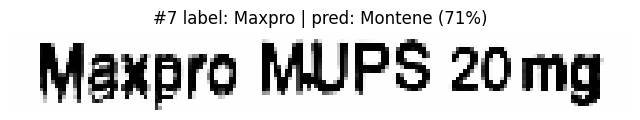

In [20]:
def show(i):
    r = sus.loc[i]
    plt.figure(figsize=(8, 3)); plt.imshow(Image.open(r.path).convert('L'), cmap='gray'); plt.axis('off')
    plt.title(f'#{i} label: {r.medicine} | pred: {r.pred} ({r.conf:.0%})'); plt.show()

show(7)   # change the number

## Part 2 — Clean labels & advanced experiments

In [6]:
#B1. Create the label-fix list (works with old or new data.py)
!pip install -q imagehash
import sys; sys.path.insert(0, '.')
import hashlib, pandas as pd
from PIL import Image
from src.data import load_all

OUT = '/content/drive/MyDrive/label_fixes.csv'
try:
    fr = load_all(DATA_ROOT, use_fixes=False)   # new data.py
except TypeError:
    fr = load_all(DATA_ROOT)                    # old data.py (no fixes yet = raw data)

seen, rows = {}, []
for split in ['train', 'val', 'test']:          # keep the copy in the earliest split
    for p in fr[split].path:
        h = hashlib.md5(Image.open(p).convert('L').tobytes()).hexdigest()
        if h in seen:
            if split != 'train':
                rows.append((split, p.split('/')[-1], 'DROP'))
        else:
            seen[h] = (split, p)
auto = pd.DataFrame(rows, columns=['split', 'image', 'correct_label'])
print(auto.split.value_counts())

manual = pd.DataFrame([
    ('train', '2527.png', 'Flugal'),   # was Progut
    ('train', '1897.png', 'Sergel'),   # was Maxpro
    ('test',  '291.png',  'Fexo'),     # was Fenadin
    ('test',  '561.png',  'Opton'),    # was Nexcap
], columns=['split', 'image', 'correct_label'])
manual = manual[~manual.set_index(['split', 'image']).index.isin(auto.set_index(['split', 'image']).index)]

fixes = pd.concat([manual, auto], ignore_index=True)
fixes.to_csv(OUT, index=False)
print(f'Saved {len(fixes)} rows ({len(manual)} relabels, {len(auto)} drops) to {OUT}')

split
test    65
val     36
Name: count, dtype: int64
Saved 104 rows (3 relabels, 101 drops) to /content/drive/MyDrive/label_fixes.csv


In [7]:
#B2. Check the new code + label fixes are active
!git log --oneline -3
import sys; sys.path.insert(0, '.')
from src.data import load_all
print({k: len(v) for k, v in load_all(DATA_ROOT).items()})

d22ed91 (HEAD -> main, origin/main, origin/HEAD) Advanced training, label fixes, Ketoconazole KB entries
0111afb Set repo URL in Colab notebook
42c866e Initial project structure: data loader, training, evaluation, Bangla KB, Colab notebook
[label_fixes] relabelled 3, dropped 101 images
{'test': 715, 'train': 3120, 'val': 744}


In [8]:
#B3. Honest score of the old model on the clean test set
!python -m src.evaluate --data_root "$DATA_ROOT" --run_dir /content/drive/MyDrive/rx_runs/effb0

[label_fixes] relabelled 3, dropped 101 images
{
  "split": "test",
  "n": 715,
  "top1_acc": 0.9132867132867133,
  "top5_acc": 0.9664335664335665,
  "macro_f1": 0.9055701209654793,
  "generic_acc": 0.9524475524475524
}
62 misclassified images listed in /content/drive/MyDrive/rx_runs/effb0/misclassified.csv


In [9]:
#B4-A. Exp A — rectangular input (~15 min)
!python -m src.train --data_root "$DATA_ROOT" --out_dir /content/drive/MyDrive/rx_runs/A_rect \
    --model efficientnet_b0 --input_hw 128 384
!python -m src.evaluate --data_root "$DATA_ROOT" --run_dir /content/drive/MyDrive/rx_runs/A_rect

Device: cuda (Tesla T4)
[label_fixes] relabelled 3, dropped 101 images
test :   715 images, 78 classes
train:  3120 images, 78 classes
val  :   744 images, 78 classes
/content/bangla-prescription-analyzer/src/train.py:161: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()
ep   1 | train loss 4.693 acc 0.019 | val loss 4.298 top1 0.044 top5 0.168 | 24.5s
  ✓ new best (acc) -> saved best.pt
ep   2 | train loss 3.973 acc 0.122 | val loss 3.156 top1 0.347 top5 0.613 | 24.7s
  ✓ new best (acc) -> saved best.pt
ep   3 | train loss 2.885 acc 0.403 | val loss 2.047 top1 0.617 top5 0.853 | 20.7s
  ✓ ne

In [ ]:
#B4-B. Exp B — + strong augmentation, MixUp/CutMix, EMA (~25 min)
!python -m src.train --data_root "$DATA_ROOT" --out_dir /content/drive/MyDrive/rx_runs/B_strong \
    --model efficientnet_b0 --input_hw 128 384 --aug strong --mixup --ema 0.999 \
    --select loss --epochs 60 --patience 15
!python -m src.evaluate --data_root "$DATA_ROOT" --run_dir /content/drive/MyDrive/rx_runs/B_strong

Device: cuda (Tesla T4)
[label_fixes] relabelled 3, dropped 101 images
test :   715 images, 78 classes
train:  3120 images, 78 classes
val  :   744 images, 78 classes
/content/bangla-prescription-analyzer/src/train.py:161: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()
ep   1 | train loss 4.716 acc 0.012 | val loss 4.651 top1 0.013 top5 0.067 | 107.4s
  ✓ new best (loss) -> saved best.pt
ep   2 | train loss 4.267 acc 0.063 | val loss 4.633 top1 0.019 top5 0.067 | 102.1s
  ✓ new best (loss) -> saved best.pt
ep   3 | train loss 3.524 acc 0.208 | val loss 4.605 top1 0.020 top5 0.070 | 101.5s
 

In [5]:
!python -m src.evaluate --data_root "$DATA_ROOT" --run_dir /content/drive/MyDrive/rx_runs/B_strong

[label_fixes] relabelled 3, dropped 101 images
{
  "split": "test",
  "n": 715,
  "top1_acc": 0.9048951048951049,
  "top5_acc": 0.9706293706293706,
  "macro_f1": 0.8978055007452016,
  "generic_acc": 0.9426573426573427
}
68 misclassified images listed in /content/drive/MyDrive/rx_runs/B_strong/misclassified.csv


effb0     62 wrong
A_rect    71 wrong
B_strong  68 wrong

Wrong in all 3 runs: 39  |  all 3 predict the SAME wrong name: 20


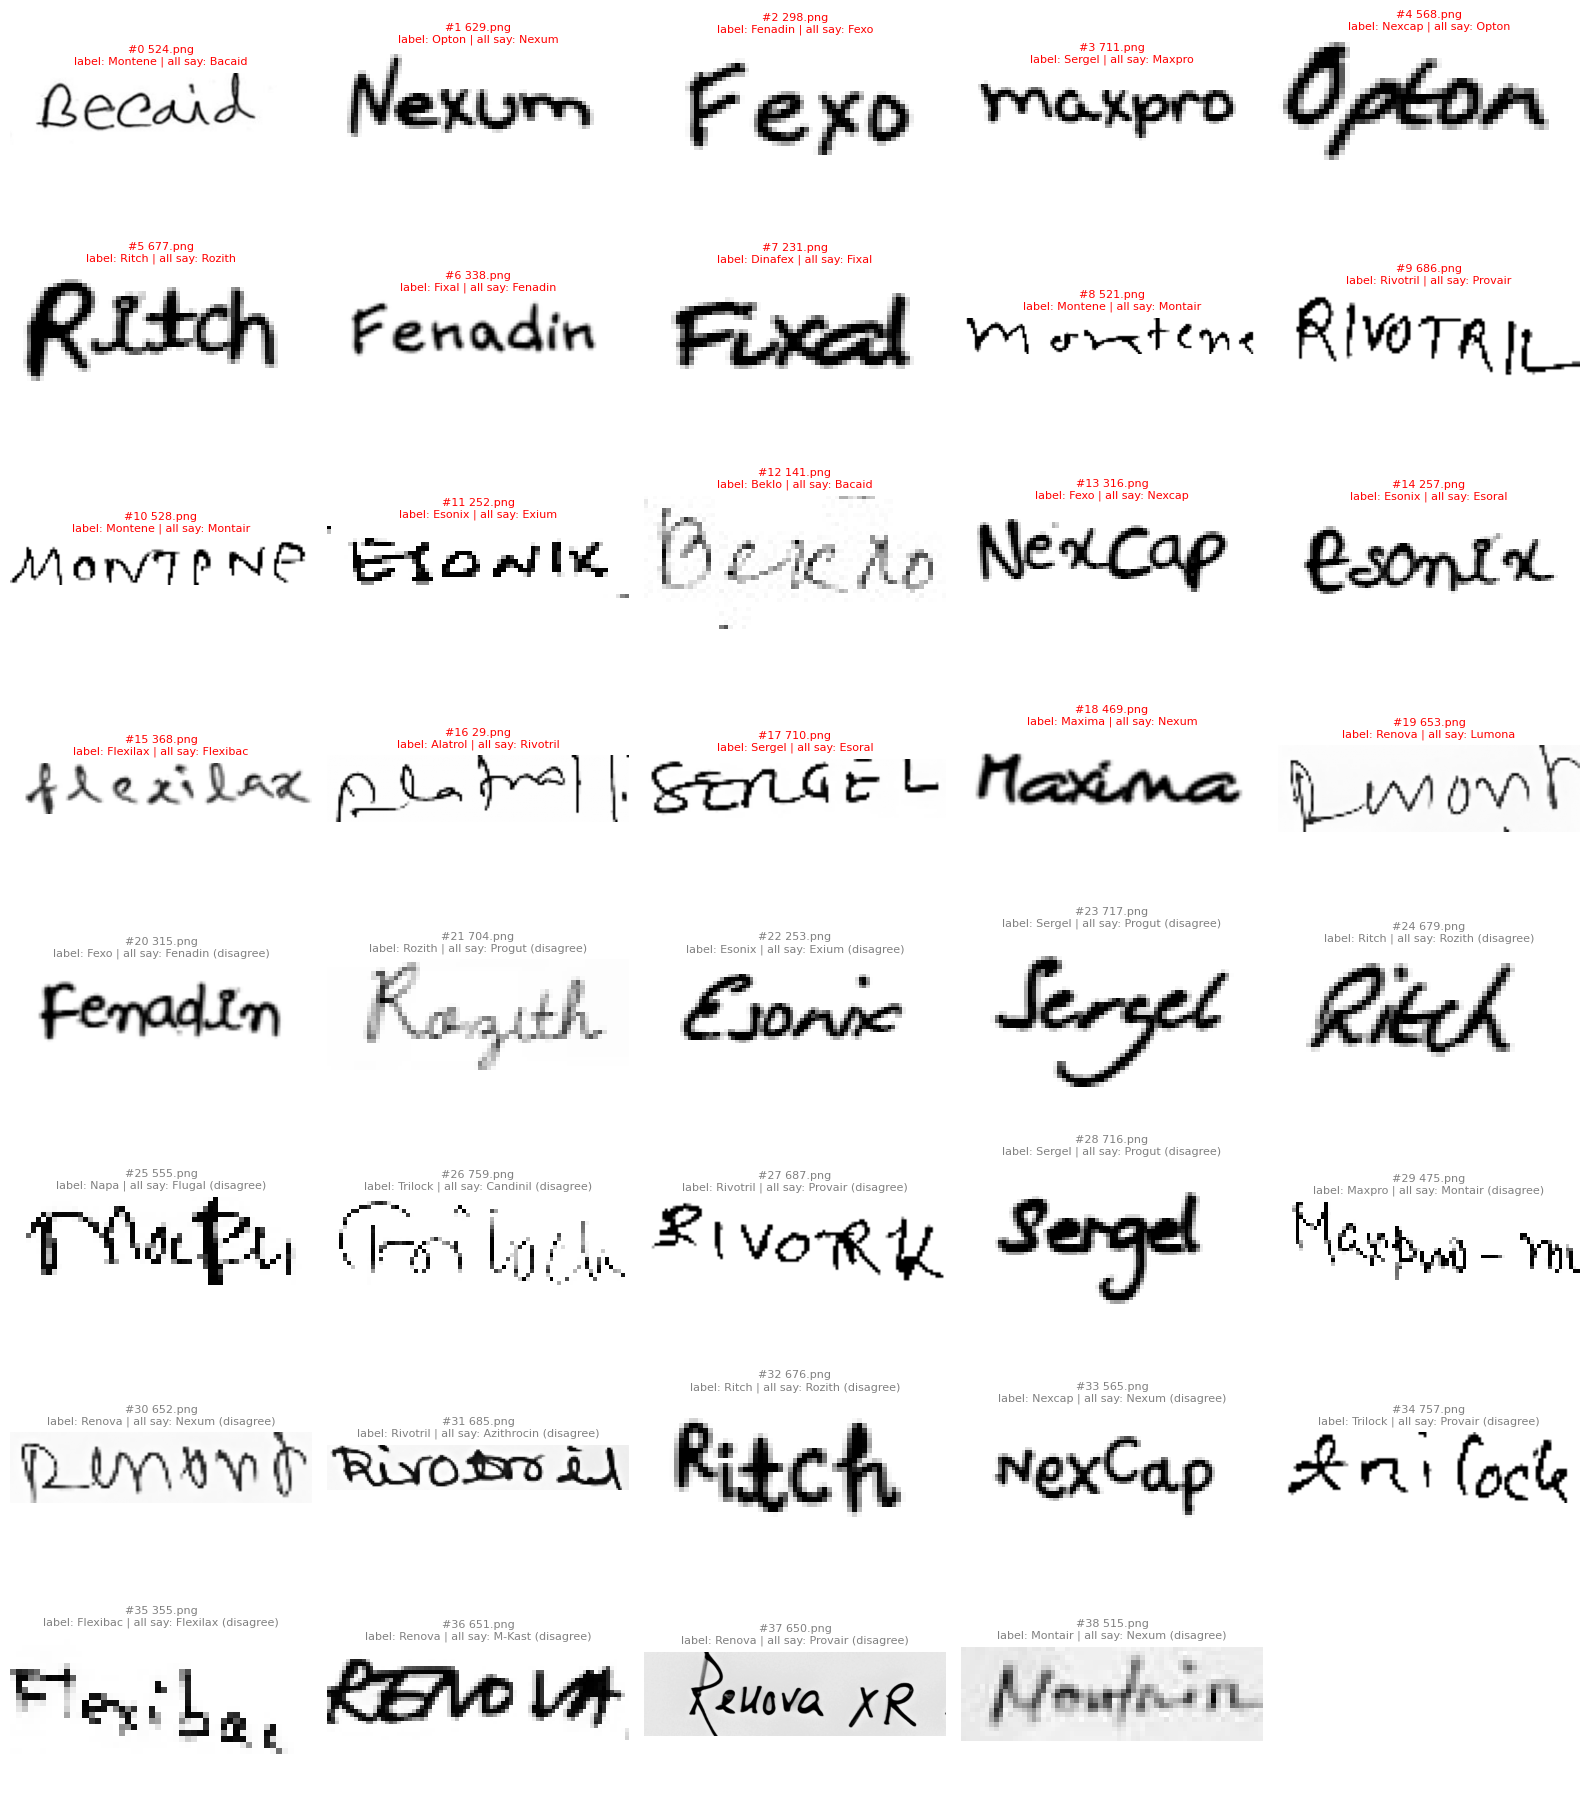

In [6]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image

runs = ['effb0', 'A_rect', 'B_strong']
W = {r: pd.read_csv(f'/content/drive/MyDrive/rx_runs/{r}/misclassified.csv') for r in runs}
for r, w in W.items(): print(f'{r:9s} {len(w)} wrong')

# images wrong in ALL runs
common = set.intersection(*[set(w.path) for w in W.values()])
m = W['B_strong'][W['B_strong'].path.isin(common)].copy()
for r in runs:
    m[f'pred_{r}'] = m.path.map(W[r].set_index('path').pred)
m['same_pred'] = m[[f'pred_{r}' for r in runs]].nunique(axis=1) == 1
m = m.sort_values(['same_pred', 'conf'], ascending=False).reset_index(drop=True)
print(f'\nWrong in all 3 runs: {len(m)}  |  all 3 predict the SAME wrong name: {m.same_pred.sum()}')

n = len(m)
fig, axes = plt.subplots((n + 4) // 5, 5, figsize=(16, 2.3 * ((n + 4) // 5)))
for ax in axes.flat: ax.axis('off')
for ax, (i, r) in zip(axes.flat, m.iterrows()):
    ax.imshow(Image.open(r.path).convert('L'), cmap='gray')
    ax.set_title(f"#{i} {r.path.split('/')[-1]}\nlabel: {r.medicine} | all say: {r.pred}"
                 + ('' if r.same_pred else ' (disagree)'), fontsize=8,
                 color='red' if r.same_pred else 'gray')
plt.tight_layout(); plt.show()
m[['path', 'medicine', 'pred', 'conf', 'same_pred']].to_csv('/content/drive/MyDrive/common_errors.csv')

In [5]:
for r in ['effb0', 'A_rect', 'B_strong']:
    !python -m src.evaluate --data_root "$DATA_ROOT" --run_dir /content/drive/MyDrive/rx_runs/{r}

[label_fixes] relabelled 12, dropped 102 images
{
  "split": "test",
  "n": 714,
  "top1_acc": 0.927170868347339,
  "top5_acc": 0.9803921568627451,
  "macro_f1": 0.9207860703566203,
  "generic_acc": 0.9565826330532213
}
52 misclassified images listed in /content/drive/MyDrive/rx_runs/effb0/misclassified.csv
[label_fixes] relabelled 12, dropped 102 images
{
  "split": "test",
  "n": 714,
  "top1_acc": 0.9131652661064426,
  "top5_acc": 0.9705882352941176,
  "macro_f1": 0.9061407219972145,
  "generic_acc": 0.9495798319327731
}
62 misclassified images listed in /content/drive/MyDrive/rx_runs/A_rect/misclassified.csv
[label_fixes] relabelled 12, dropped 102 images
{
  "split": "test",
  "n": 714,
  "top1_acc": 0.9187675070028011,
  "top5_acc": 0.9845938375350141,
  "macro_f1": 0.9131363853815458,
  "generic_acc": 0.9467787114845938
}
58 misclassified images listed in /content/drive/MyDrive/rx_runs/B_strong/misclassified.csv


In [6]:
#B6. Ensemble + TTA
import sys; sys.path.insert(0, '.')
import numpy as np, torch
from torch.utils.data import DataLoader
from src.data import LabelMap, PrescriptionWords, load_all, transforms_from_cfg
from src.model import load_checkpoint

RUNS = ['/content/drive/MyDrive/rx_runs/effb0',
        '/content/drive/MyDrive/rx_runs/A_rect',
        '/content/drive/MyDrive/rx_runs/B_strong']
device = 'cuda' if torch.cuda.is_available() else 'cpu'
test_df = load_all(DATA_ROOT)['test']

@torch.no_grad()
def predict_tta(run, shifts=(0, -6, 6)):
    lm = LabelMap.load(f'{run}/label_map.json')
    model, cfg = load_checkpoint(f'{run}/best.pt', len(lm.classes), device)
    dl = DataLoader(PrescriptionWords(test_df, lm, transforms_from_cfg(cfg)), batch_size=64, num_workers=2)
    probs, ys = [], []
    for x, y in dl:
        x = x.to(device); p = 0
        for s in shifts:
            for dims in ((3,), (2,)):
                if s == 0 and dims == (2,):
                    continue
                p = p + model(torch.roll(x, s, dims=dims) if s else x).softmax(1)
        probs.append((p / p.sum(1, keepdim=True)).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy(), lm

all_p = {}
for run in RUNS:
    p, y, lm = predict_tta(run)
    name = run.split('/')[-1]
    all_p[name] = p
    print(f'{name:9s}: TTA top1 = {(p.argmax(1) == y).mean():.4f}')

gen = np.array([lm.generic_of[c] for c in lm.classes])
def score(names):
    e = np.mean([all_p[n] for n in names], 0).argmax(1)
    return (e == y).mean(), (gen[e] == gen[y]).mean()

import itertools
print('\nEnsembles:')
for k in (2, 3):
    for combo in itertools.combinations(all_p, k):
        t1, g = score(combo)
        print(f'  {" + ".join(combo):30s} top1 = {t1:.4f} | generic = {g:.4f}')

[label_fixes] relabelled 12, dropped 102 images
effb0    : TTA top1 = 0.9286
A_rect   : TTA top1 = 0.9090
B_strong : TTA top1 = 0.9230

Ensembles:
  effb0 + A_rect                 top1 = 0.9356 | generic = 0.9664
  effb0 + B_strong               top1 = 0.9398 | generic = 0.9650
  A_rect + B_strong              top1 = 0.9272 | generic = 0.9608
  effb0 + A_rect + B_strong      top1 = 0.9398 | generic = 0.9678
